#### 前提

In [1]:
%pip install -r requirements.txt

Note: you may need to restart the kernel to use updated packages.


In [2]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

path = "../data/outlier_deal_for_nan_exp1.csv"

df = pd.read_csv(path)

In [3]:
alertness_distribution = (
    df
    .groupby("Message Group")["Alertness Level"]
    .value_counts()
    .rename("count")
    .reset_index()
)

affect_distribution = (
    df
    .groupby("Message Group")["Affect Level"]
    .value_counts()
    .rename("count")
    .reset_index()
)

In [4]:
print("Alertness:")
print(alertness_distribution.shape)

print("Affect:")
print(affect_distribution.shape)

Alertness:
(279, 3)
Affect:
(280, 3)


In [5]:
print(
    alertness_distribution.groupby("Message Group")["count"].sum()
)

print(
    affect_distribution.groupby("Message Group")["count"].sum()
)

Message Group
negative    2977
neutral     2964
positive    2751
Name: count, dtype: int64
Message Group
negative    2977
neutral     2964
positive    2751
Name: count, dtype: int64


#### 感情グループ別 選択数プロット

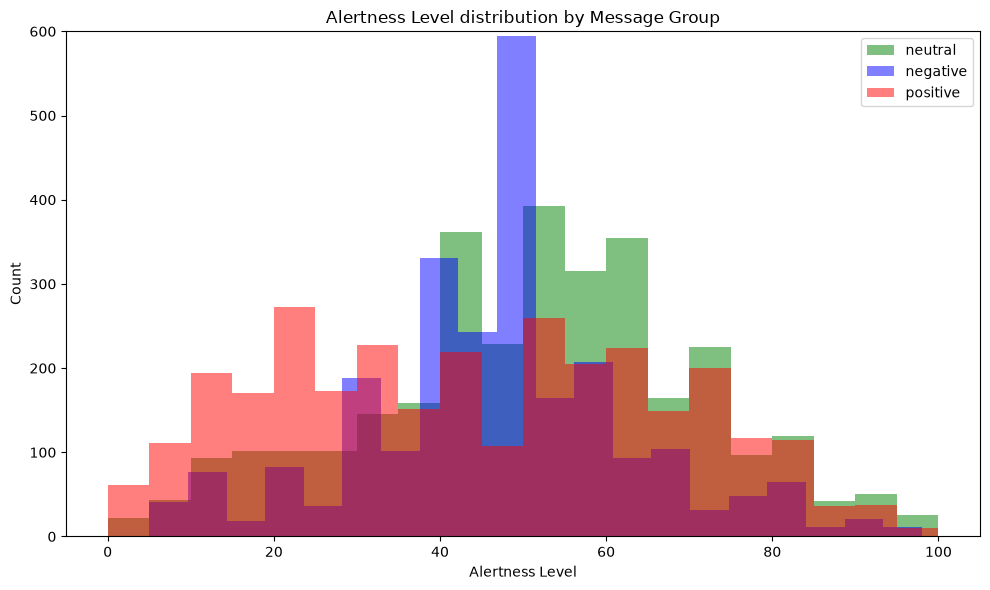

In [31]:
import matplotlib.pyplot as plt

groups = ["neutral", "negative", "positive"]
colors = {
    "neutral": "green",
    "positive": "red",
    "negative": "blue"
}

plt.figure(figsize=(10, 6))

for group in groups:
    values = df.loc[
        df["Message Group"] == group,
        "Alertness Level"
    ].dropna()

    plt.hist(
        values,
        bins=20,
        alpha=0.5,
        label=group,
        color=colors[group]
    )

plt.xlabel("Alertness Level")
plt.ylabel("Count")
plt.title("Alertness Level distribution by Message Group")
plt.legend()
plt.ylim(0,600)
plt.tight_layout()
plt.show()

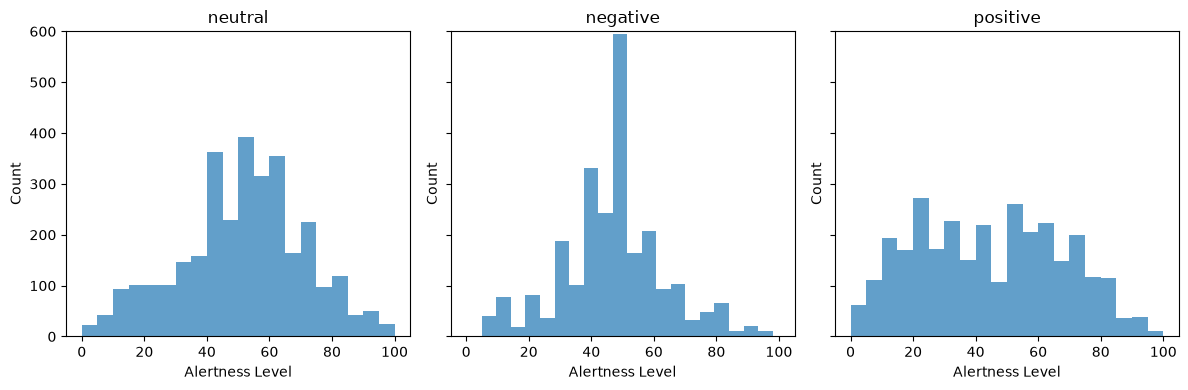

In [32]:
import matplotlib.pyplot as plt

groups = ["neutral", "negative", "positive"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    sharex=True,
    sharey=True
)

for ax, group in zip(axes, groups):

    values = df.loc[
        df["Message Group"] == group,
        "Alertness Level"
    ].dropna()

    ax.hist(
        values,
        bins=20,
        alpha=0.7
    )

    ax.set_title(group)
    ax.set_xlabel("Alertness Level")
    ax.set_ylabel("Count")
plt.ylim(0,600)
plt.tight_layout()
plt.show()

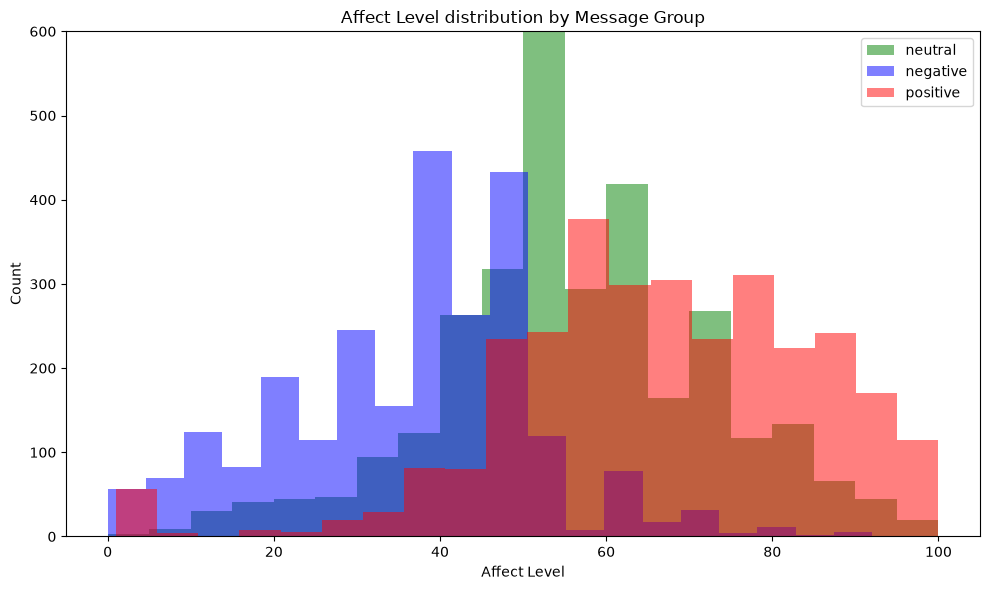

In [33]:
plt.figure(figsize=(10, 6))

for group in groups:
    values = df.loc[
        df["Message Group"] == group,
        "Affect Level"
    ].dropna()

    plt.hist(
        values,
        bins=20,
        alpha=0.5,
        label=group,
        color=colors[group]
    )

plt.xlabel("Affect Level")
plt.ylabel("Count")
plt.title("Affect Level distribution by Message Group")
plt.legend()
plt.ylim(0,600)
plt.tight_layout()
plt.show()

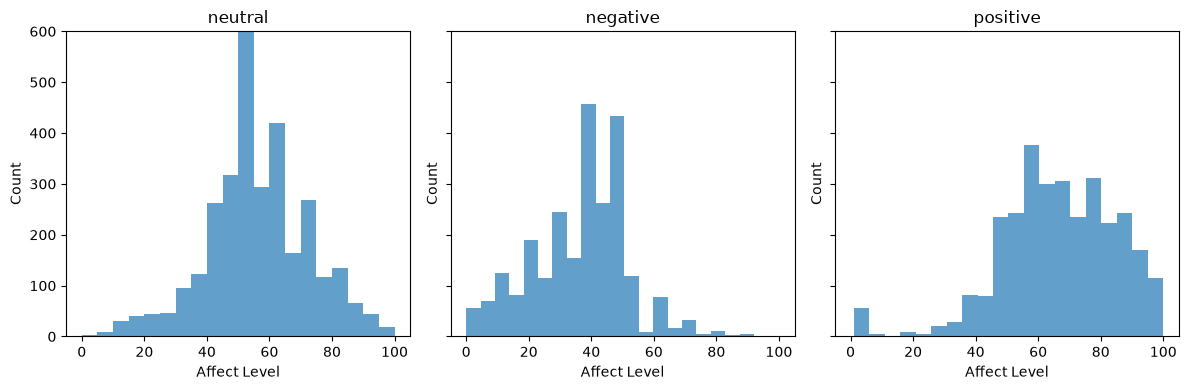

In [34]:
import matplotlib.pyplot as plt

groups = ["neutral", "negative", "positive"]

fig, axes = plt.subplots(
    1, 3,
    figsize=(12, 4),
    sharex=True,
    sharey=True
)

for ax, group in zip(axes, groups):

    values = df.loc[
        df["Message Group"] == group,
        "Affect Level"
    ].dropna()

    ax.hist(
        values,
        bins=20,
        alpha=0.7
    )

    ax.set_title(group)
    ax.set_xlabel("Affect Level")
    ax.set_ylabel("Count")
plt.ylim(0,600)
plt.tight_layout()
plt.show()

#### 実験1参照点なし　選択数＊スライダー

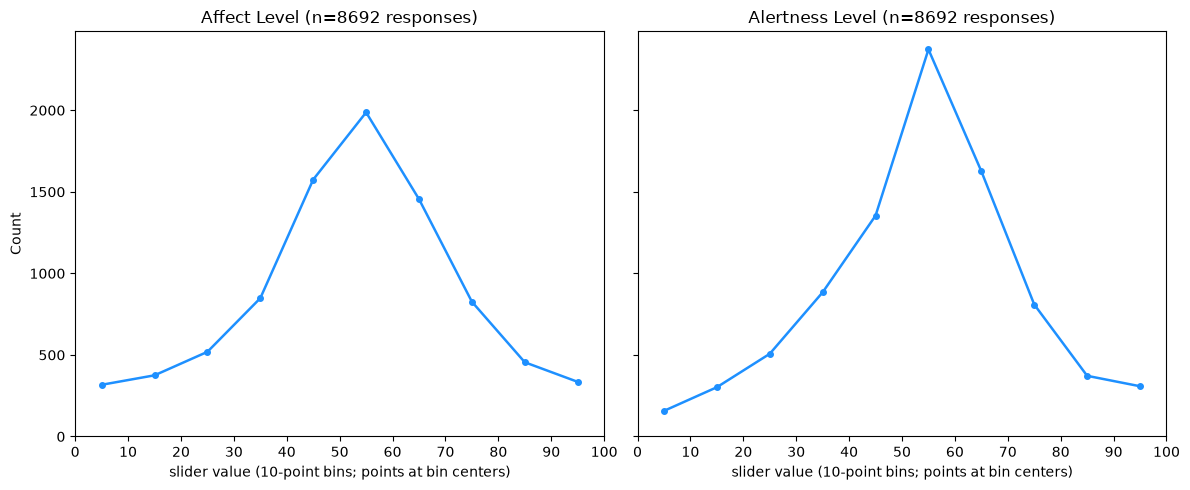

In [21]:
import numpy as np
import matplotlib.pyplot as plt

cols = ["Affect Level", "Alertness Level"]
bins = np.arange(0, 101, 10)
mid = bins[:-1] + 5

USE_RATE = False                                      # True: 選択率(%)、False: 件数
YMAX = 35                                            # 選択率のときの縦軸の上限(%)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)   # 縦軸を共有して、2つを同じ目盛りで比べる
for ax, col in zip(axes, cols):
    values = df[col].dropna()                        # 感情群・参照点を区別せず、全データをまとめる
    h, _ = np.histogram(values, bins=bins)
    y = h / h.sum() * 100 if USE_RATE else h

    ax.plot(mid, y, marker="o", ms=4, lw=1.8, color="#1e90ff")
    ax.set_title(f"{col} (n={len(values)} responses)")
    ax.set_xlabel("slider value (10-point bins; points at bin centers)")
    ax.set_xticks(bins)
    ax.set_xlim(0, 100)

axes[0].set_ylabel("Percent of responses (%)" if USE_RATE else "Count")
if USE_RATE:
    axes[0].set_ylim(0, YMAX)
else:
    axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

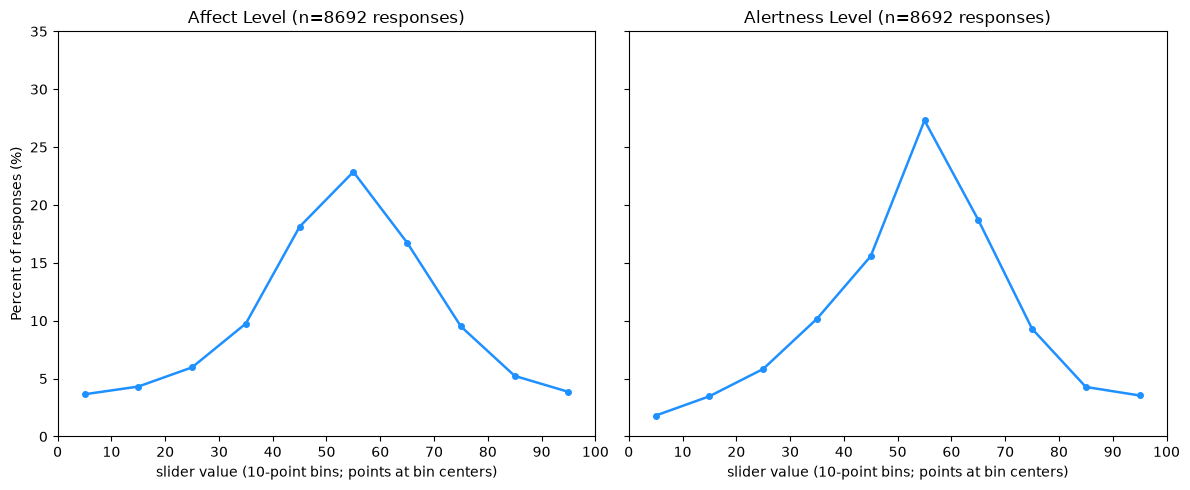

In [22]:
import numpy as np
import matplotlib.pyplot as plt

cols = ["Affect Level", "Alertness Level"]
bins = np.arange(0, 101, 10)
mid = bins[:-1] + 5

USE_RATE = True                                      # True: 選択率(%)、False: 件数
YMAX = 35                                            # 選択率のときの縦軸の上限(%)

fig, axes = plt.subplots(1, 2, figsize=(12, 5), sharey=True)   # 縦軸を共有して、2つを同じ目盛りで比べる
for ax, col in zip(axes, cols):
    values = df[col].dropna()                        # 感情群・参照点を区別せず、全データをまとめる
    h, _ = np.histogram(values, bins=bins)
    y = h / h.sum() * 100 if USE_RATE else h

    ax.plot(mid, y, marker="o", ms=4, lw=1.8, color="#1e90ff")
    ax.set_title(f"{col} (n={len(values)} responses)")
    ax.set_xlabel("slider value (10-point bins; points at bin centers)")
    ax.set_xticks(bins)
    ax.set_xlim(0, 100)

axes[0].set_ylabel("Percent of responses (%)" if USE_RATE else "Count")
if USE_RATE:
    axes[0].set_ylim(0, YMAX)
else:
    axes[0].set_ylim(bottom=0)
plt.tight_layout()
plt.show()

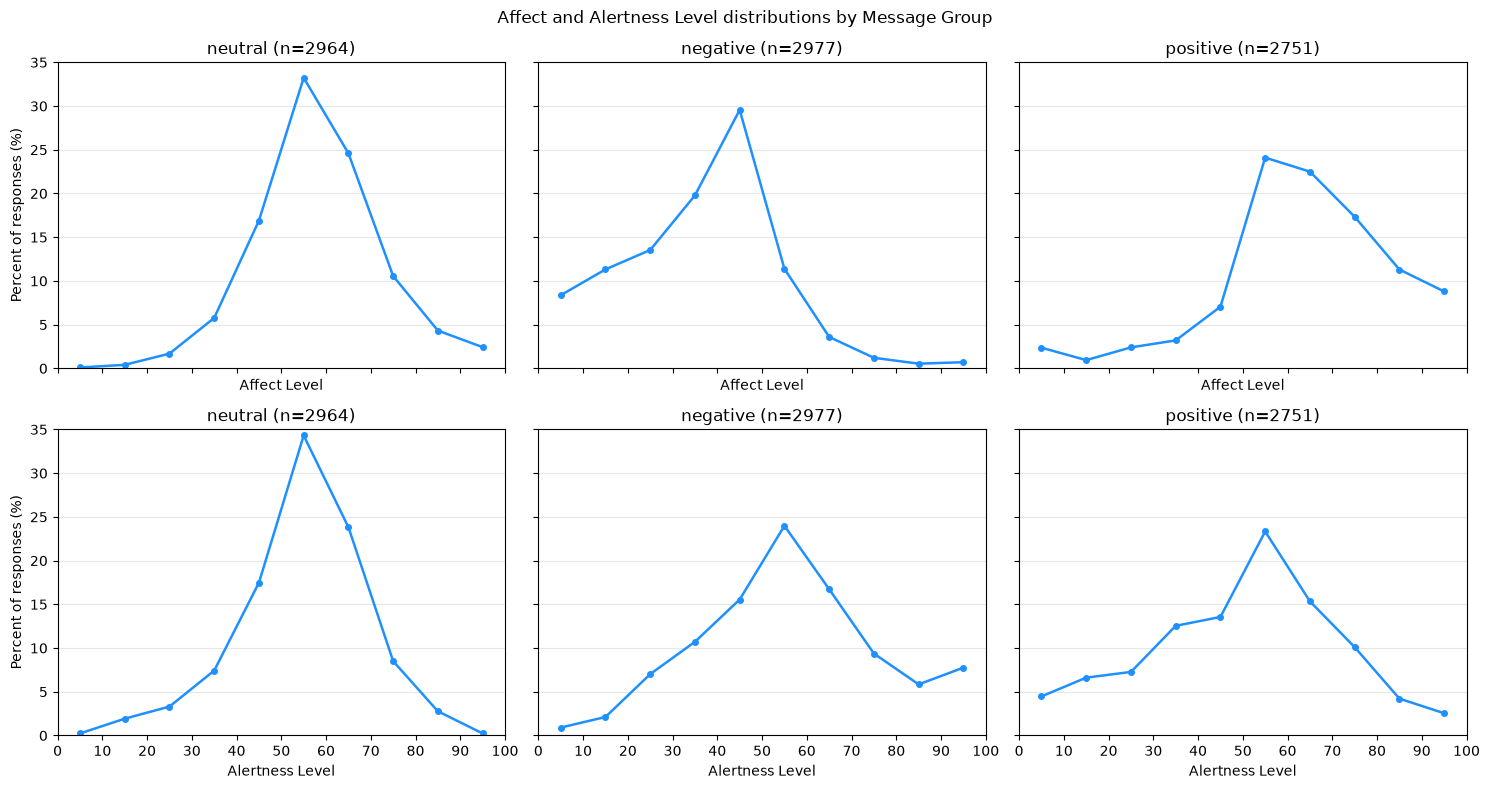

In [23]:
import numpy as np
import matplotlib.pyplot as plt

cols = ["Affect Level", "Alertness Level"]
groups = ["neutral", "negative", "positive"]

bins = np.arange(0, 101, 10)
mid = bins[:-1] + 5

USE_RATE = True  # True: 選択率(%)、False: 件数
YMAX = 35         # 選択率のときの縦軸の上限(%)

fig, axes = plt.subplots(
    2, 3,
    figsize=(15, 8),
    sharex=True,
    sharey=True
)

for row, col in enumerate(cols):
    for ax, group in zip(axes[row], groups):

        # 感情グループ別にデータを抽出
        values = df.loc[
            df["Message Group"] == group,
            col
        ].dropna()

        # 10点刻みで集計
        h, _ = np.histogram(values, bins=bins)

        # 件数または選択率に変換
        y = h / h.sum() * 100 if USE_RATE and h.sum() > 0 else h

        # 折れ線グラフ
        ax.plot(
            mid, y,
            marker="o",
            ms=4,
            lw=1.8,
            color="#1e90ff"
        )

        ax.set_title(f"{group} (n={len(values)})")
        ax.set_xlabel(col)
        ax.set_xticks(bins)
        ax.set_xlim(0, 100)
        ax.grid(axis="y", alpha=0.3)

axes[0, 0].set_ylabel(
    "Percent of responses (%)" if USE_RATE else "Count"
)
axes[1, 0].set_ylabel(
    "Percent of responses (%)" if USE_RATE else "Count"
)

if USE_RATE:
    axes[0, 0].set_ylim(0, YMAX)
else:
    for ax in axes.flat:
        ax.set_ylim(bottom=0)

fig.suptitle("Affect and Alertness Level distributions by Message Group")
plt.tight_layout()
plt.show()

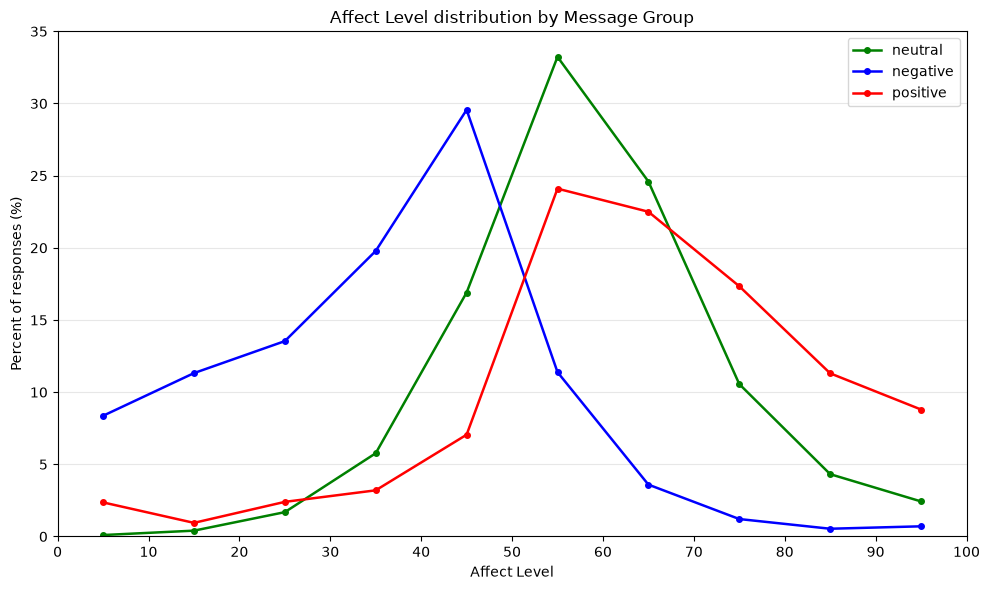

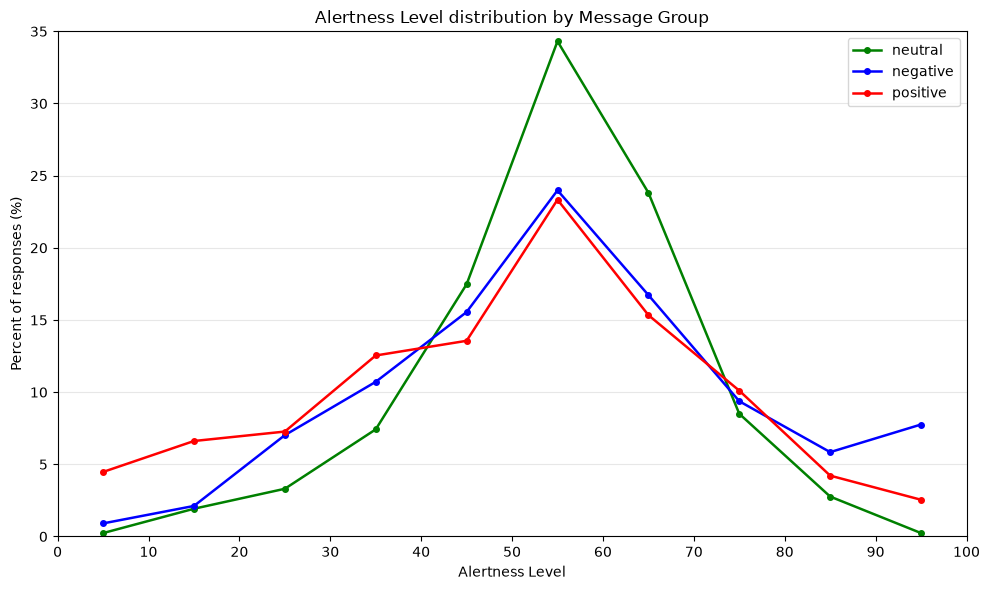

In [24]:
import numpy as np
import matplotlib.pyplot as plt

cols = ["Affect Level", "Alertness Level"]
groups = ["neutral", "negative", "positive"]

colors = {
    "neutral": "green",
    "negative": "blue",
    "positive": "red"
}

bins = np.arange(0, 101, 10)
mid = bins[:-1] + 5

USE_RATE = True  # True: 選択率(%)、False: 件数
YMAX = 35

for col in cols:
    plt.figure(figsize=(10, 6))

    for group in groups:
        values = df.loc[
            df["Message Group"] == group,
            col
        ].dropna()

        h, _ = np.histogram(values, bins=bins)

        y = h / h.sum() * 100 if USE_RATE and h.sum() > 0 else h

        plt.plot(
            mid,
            y,
            marker="o",
            ms=4,
            lw=1.8,
            label=group,
            color=colors[group]
        )

    plt.xlabel(col)
    plt.ylabel("Percent of responses (%)" if USE_RATE else "Count")
    plt.title(f"{col} distribution by Message Group")
    plt.xticks(bins)
    plt.xlim(0, 100)
    plt.legend()
    plt.grid(axis="y", alpha=0.3)

    if USE_RATE:
        plt.ylim(0, YMAX)
    else:
        plt.ylim(bottom=0)

    plt.tight_layout()
    plt.show()